# Analysis of the results (notebook 04)

Notebooks 02 and 03 run the models; this one only reads what they saved in 
and . Nothing is fitted here. It compares all models on the same five splits:
headline metrics, validation versus test, generalisation gap, per-seed spread, curves and
confusion matrices of seed 0, the training curves of the fine-tuned model, and which frauds
each model catches or misses.

Run time: under a minute.

In [1]:
import sys, os; os.chdir(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else None; sys.path.insert(0, "."); import warnings
import glob, json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay

from modules import data_helper as dh
from modules import features as ft
from modules import results_helper as rh

DATA = "../data/fake_job_postings.csv"

In [2]:
SEED = 0
SPLIT_PATH = "splits/seed0.npz"
OUT_CLASSICAL = "outputs/classical"
OUT_DEEP = "outputs/deep"
GROUPS = ["classical", "deep"]

dh.seed_everything(SEED)
sns.set_theme(style="whitegrid")

In [3]:
DIRS = {"classical": OUT_CLASSICAL, "deep": OUT_DEEP}


class StopExecution(Exception):
    """Stops the notebook quietly when there is nothing to report."""

    def _render_traceback_(self):
        pass  # IPython hook: an empty traceback, so the notebook just stops

## Load the saved results

`results_helper.load_results` collects one row per (model, seed) from the JSON
files of the groups listed in `GROUPS` (deep results only when `outputs/deep/` is non-empty). If
nothing is found we stop here with a message instead of crashing.

In [ ]:
# Result folders of the wanted groups that exist and are not empty.
dirs = [d for g, d in DIRS.items() if g in GROUPS and os.path.isdir(d) and os.listdir(d)]

# One row per (model, seed) from the saved json files.
res = rh.load_results(*dirs) if dirs else pd.DataFrame(columns=["group"])
res = res[res["group"].isin(GROUPS)]
if res.empty:
    print("No result files were found. Looked in:", dirs)
    print("Run the experiment cells of this notebook first, then re-run this section.")
    raise StopExecution
print(f"{len(res)} runs found: {res['model'].nunique()} models, "
      f"seeds {sorted(int(x) for x in res['seed'].unique())}")
if "verified_artifact" in res.columns and not res["verified_artifact"].all():
    print("WARNING: historical JSON/NPZ lacks verified provenance. "
          "These scores are for reference only; regenerate before final claims.")
if ((res["model"].str.startswith("dummy")) & (res["thr"] == 0)).any():
    print("WARNING: legacy dummy baseline used threshold=0 and predicted all jobs fraud. "
          "Its F1/recall/confusion counts are invalid; rerun notebook 02.")

## Which runs were found

Each cell counts finished runs; a full grid has exactly one run per (model, seed).

In [5]:
res.groupby(["model", "seed"]).size().unstack(fill_value=0)

seed,0,1,2,3,4
model,,,,,
bert_distilbert-base-uncased,1,1,1,1,1
dummy_majority,1,1,1,1,1
dummy_stratified,1,1,1,1,1
emb_logreg,1,1,1,1,1
emb_mlp,1,1,1,1,1
logreg,1,1,1,1,1
logreg_bm25,1,1,1,1,1
mlp,1,1,1,1,1
tree,1,1,1,1,1


## Headline test metrics

Mean and standard deviation over seeds, sorted by mean test PR-AUC. The dummy rows
are the floor every real model has to beat. With a single seed there is no standard
deviation and only the mean is shown.

In [6]:
def fmt(col):
    """mean +- std over seeds for one metric; a lone seed has no std."""
    g = res.groupby("model")[col]
    return [f"{m:.3f} +- {s:.3f}" if pd.notna(s) else f"{m:.3f}"
            for m, s in zip(g.mean(), g.std())]


# Models ordered by mean test PR-AUC, best first.
order = res.groupby("model")["test_pr_auc"].mean().sort_values(ascending=False).index

# The headline table: mean +- std over seeds.
pd.DataFrame({
    "seeds": res.groupby("model").size(),
    "test PR-AUC": fmt("test_pr_auc"),
    "test F1": fmt("test_f1"),
    "test precision": fmt("test_precision"),
    "test recall": fmt("test_recall"),
}).loc[order]

,seeds,test PR-AUC,test F1,test precision,test recall
model,,,,,
logreg_bm25,5,0.847 +- 0.073,0.804 +- 0.055,0.856 +- 0.034,0.760 +- 0.081
mlp,5,0.846 +- 0.077,0.787 +- 0.081,0.863 +- 0.051,0.726 +- 0.106
bert_distilbert-base-uncased,5,0.831 +- 0.066,0.771 +- 0.072,0.860 +- 0.076,0.708 +- 0.112
logreg,5,0.821 +- 0.063,0.772 +- 0.042,0.827 +- 0.052,0.726 +- 0.053
emb_mlp,5,0.632 +- 0.092,0.598 +- 0.100,0.735 +- 0.029,0.517 +- 0.145
emb_logreg,5,0.524 +- 0.060,0.520 +- 0.028,0.551 +- 0.049,0.495 +- 0.044
tree,5,0.402 +- 0.066,0.501 +- 0.055,0.434 +- 0.054,0.634 +- 0.165
dummy_stratified,5,0.049 +- 0.001,0.093 +- 0.000,0.049 +- 0.000,1.000 +- 0.000
dummy_majority,5,0.049 +- 0.000,0.093 +- 0.000,0.049 +- 0.000,1.000 +- 0.000


Why the two dummy rows show recall 1.0: a constant score has a single possible threshold,
and picking it by F1 flags every ad as fraud. Their precision therefore equals the
share of fraud in the data, which is the floor every real model has to beat.

## Validation vs test PR-AUC

Validation is what models, hyper-parameters and thresholds were chosen on; test is
the honest number. The difference is the price of that selection.

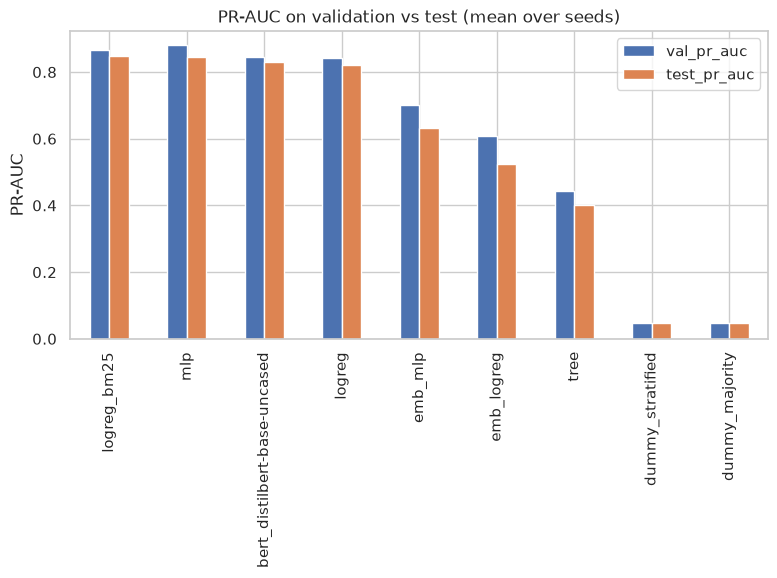

In [7]:
# Mean validation and test PR-AUC per model, then grouped bars.
means = res.groupby("model")[["val_pr_auc", "test_pr_auc"]].mean().loc[order]
ax = means.plot(kind="bar", figsize=(9, 4))
ax.set_title("PR-AUC on validation vs test (mean over seeds)")
ax.set_xlabel("")
ax.set_ylabel("PR-AUC")
plt.show()

Reading: each model has two bars, validation and test, on the same 0 to 1 scale;
the validation bar tends to sit at or above the test bar.

## Generalisation gap

Train PR-AUC minus test PR-AUC per model (mean over seeds). A large gap means the
model memorised its training rows.

In [8]:
g = res.groupby("model").agg(train_pr_auc=("train_pr_auc", "mean"),
                             test_pr_auc=("test_pr_auc", "mean"))
g["gap (train - test)"] = g["train_pr_auc"] - g["test_pr_auc"]
g.sort_values("gap (train - test)", ascending=False)

,train_pr_auc,test_pr_auc,gap (train - test)
model,,,
tree,0.638283,0.402411,0.235873
emb_mlp,0.851594,0.632343,0.219251
emb_logreg,0.713466,0.524291,0.189175
logreg,0.991778,0.820640,0.171139
bert_distilbert-base-uncased,0.989526,0.831087,0.158440
logreg_bm25,1.000000,0.847136,0.152864
mlp,0.992673,0.846210,0.146463
dummy_majority,0.048679,0.048580,0.000099
dummy_stratified,0.048816,0.048734,0.000082


## Per-seed spread

Session 7 rule of thumb: a model that wins by less than its own standard deviation
has not won. Each point is one split seed.

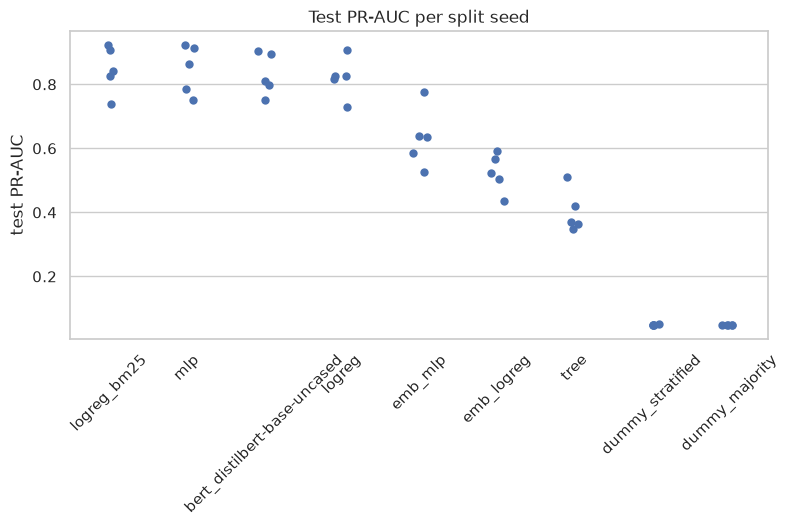

In [9]:
# One point per (model, seed).
fig, ax = plt.subplots(figsize=(9, 4))
sns.stripplot(data=res, x="model", y="test_pr_auc", order=order, ax=ax, size=6)
ax.set_title("Test PR-AUC per split seed")
ax.set_xlabel("")
ax.set_ylabel("test PR-AUC")
ax.tick_params(axis="x", rotation=45)
plt.show()

Reading: every point is one seed of one model; models whose point clouds overlap
are indistinguishable at this level of noise.

## Seed 0 in detail

The NPZ files hold y and scores for validation and test in the same row order as the
split, so curves and matrices can be rebuilt without refitting anything. If no
seed-0 run exists we stop with a message.

In [10]:
# Stop quietly when there is no seed-0 run.
seed0 = res[res["seed"] == 0]
if seed0.empty:
    print("No seed-0 runs found; the remaining sections need seed 0.")
    raise StopExecution

# Saved scores and threshold of every seed-0 model; y_test is the same for all of them.
seed_runs = {row["model"]: (rh.load_scores(DIRS[row["group"]], row["model"], 0), row["thr"])
             for _, row in seed0.iterrows()}
y_test = next(iter(seed_runs.values()))[0]["y_test"]
print("seed-0 models:", ", ".join(seed_runs))

seed-0 models: dummy_majority, dummy_stratified, logreg_bm25, logreg, mlp, tree, bert_distilbert-base-uncased, emb_logreg, emb_mlp


### Precision-recall curves on the test split (seed 0)

Built from the saved scores with sklearn's `precision_recall_curve`; the dashed line
is the fraud base rate, i.e. what random guessing scores.

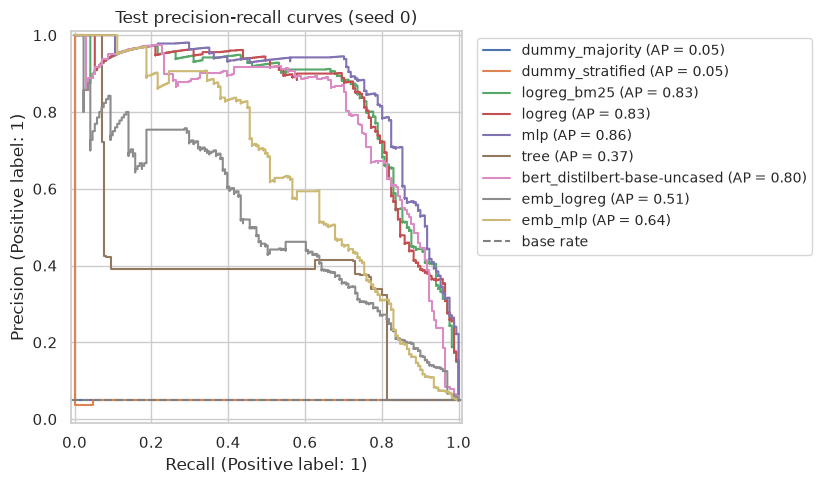

In [11]:
# One curve per model, rebuilt from the saved test scores, on shared axes.
fig, ax = plt.subplots(figsize=(9, 5))
for name, (s, thr) in seed_runs.items():
    PrecisionRecallDisplay.from_predictions(y_test, s["score_test"], name=name, ax=ax)

# Base rate: what random guessing scores.
ax.axhline(float(y_test.mean()), linestyle="--", color="grey", label="base rate")
ax.set_title("Test precision-recall curves (seed 0)")

# Legend outside the axes, to the right, so it does not cover the curves.
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize="small")
fig.tight_layout()
plt.show()

Reading: the x axis is recall, the y axis precision; closer to the top-right corner
is better, and the dashed grey line is the base rate every curve should beat.

### Confusion matrices at the validation-chosen threshold (seed 0)

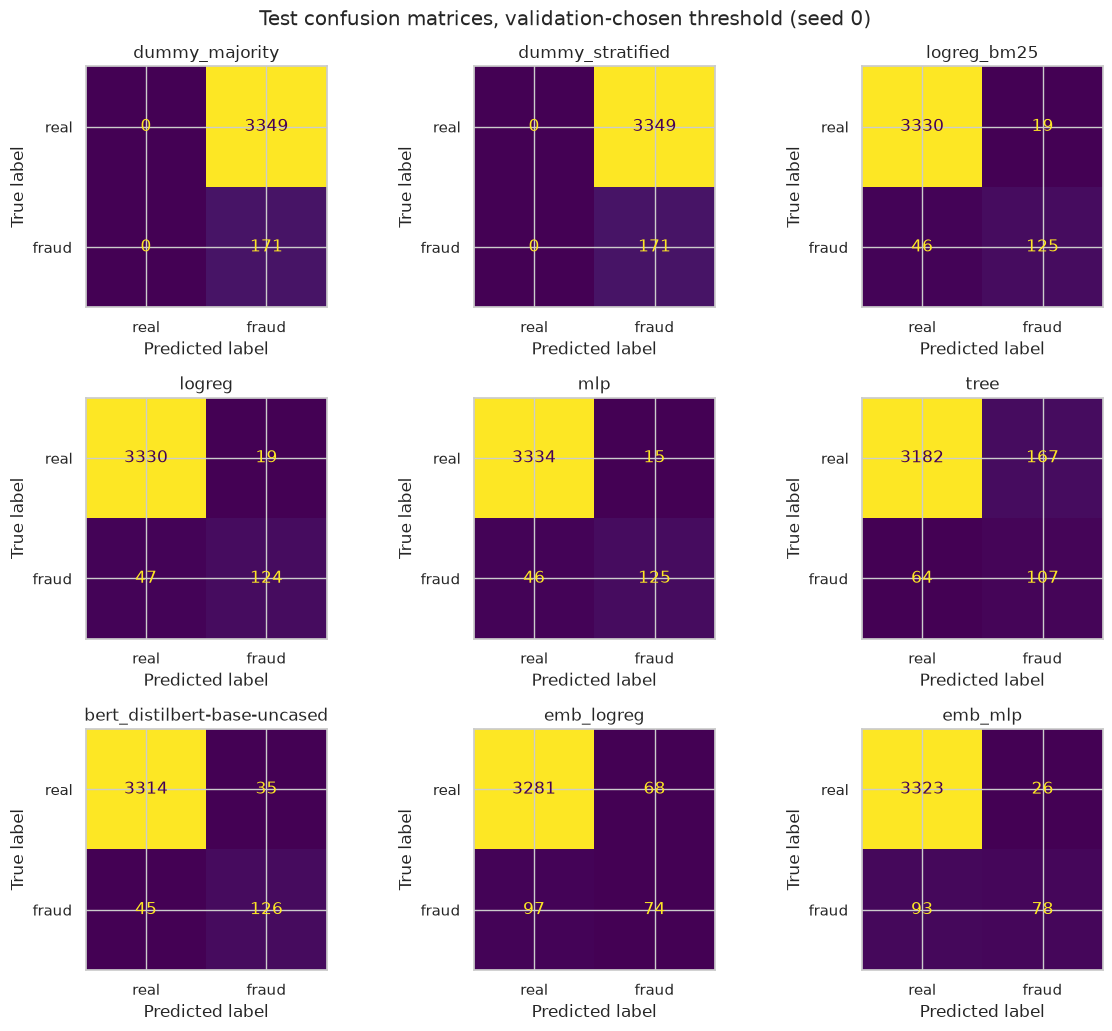

In [12]:
# Grid of panels, 3 per row, one per model.
n_cols = 3
n_rows = -(-len(seed_runs) // n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3.5 * n_rows), squeeze=False)

# Hard predictions at each model's own validation-chosen threshold.
for ax, (name, (s, thr)) in zip(axes.ravel(), seed_runs.items()):
    pred = (s["score_test"] >= thr).astype(int)
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["real", "fraud"],
                                            colorbar=False, ax=ax)
    ax.set_title(name)

# Hide unused panels.
for ax in axes.ravel()[len(seed_runs):]:
    ax.set_visible(False)
fig.suptitle("Test confusion matrices, validation-chosen threshold (seed 0)")
fig.tight_layout()
plt.show()

Reading: rows are the actual class, columns the predicted class; the diagonal holds
the correct calls.

## Fit time per model

Wall-clock seconds per run (mean over seeds and slowest seed), as recorded by the
runners.

In [13]:
res.groupby("model")["seconds"].agg(["mean", "max"]).sort_values("mean").round(1)

,mean,max
model,,
dummy_majority,0.0,0.0
dummy_stratified,0.0,0.0
emb_logreg,1.1,2.1
emb_mlp,2.6,4.3
logreg,60.8,70.3
logreg_bm25,78.6,80.0
tree,88.6,91.0
bert_distilbert-base-uncased,411.7,418.2
mlp,439.7,483.1


## Which frauds does each model catch? (seed 0)

At each model's own validation-chosen threshold: how many of the test frauds does
model A catch that model B misses. Plus the frauds caught by at least one model but
not by all.

In [14]:
# Which test frauds each model catches at its own threshold.
fraud_idx = np.where(y_test == 1)[0]
# The dummies are left out: at their threshold they flag every ad, so they "catch" every fraud.
caught = {name: frozenset(fraud_idx[s["score_test"][fraud_idx] >= thr])
          for name, (s, thr) in seed_runs.items() if not name.startswith("dummy")}

# Pairwise matrix: frauds caught by the row model but missed by the column model.
names = list(caught)
overlap = pd.DataFrame(0, index=names, columns=names)
for a in names:
    for b in names:
        overlap.loc[a, b] = len(caught[a] - caught[b])

# Frauds caught by at least one model but not by all (union minus intersection).
union = set().union(*caught.values())
inter = set(fraud_idx)
for c in caught.values():
    inter &= c
print("test frauds caught by at least one model but not by all:", len(union - inter))
overlap

test frauds caught by at least one model but not by all: 96


,logreg_bm25,logreg,mlp,tree,bert_distilbert-base-uncased,emb_logreg,emb_mlp
logreg_bm25,0,1,4,31,13,55,52
logreg,0,0,3,31,12,54,51
mlp,4,4,0,34,13,56,52
tree,13,14,16,0,19,40,38
bert_distilbert-base-uncased,14,14,14,38,0,59,55
emb_logreg,4,4,5,7,7,0,8
emb_mlp,5,5,5,9,7,12,0


Reading: cell (A, B) counts test frauds caught by A but missed by B, so the
diagonal is zero by construction; rows with large values catch much that the column
models let through.

## The ads nobody catches (seed 0)

The last Session 6 step: read the test frauds that no model flagged at its own
threshold. These are the target for the next iteration. This cell needs the seed-0
split file to look the rows up.

In [15]:
if not os.path.exists(SPLIT_PATH):
    print("splits/seed0.npz not found; cannot look up the missed ads.")
else:
    # The seed-0 test rows, in the same order as the saved scores.
    df = ft.add_engineered_features(dh.clean(dh.load_raw(DATA)))
    test = df.iloc[dh.load_splits(SPLIT_PATH, df)["test"]]

    # Ads flagged by at least one real model at its own threshold.
    caught_any = np.zeros(len(test), dtype=bool)
    for name, (s, thr) in seed_runs.items():
        if not name.startswith("dummy"):      # dummies flag every ad, so they would hide all misses
            caught_any |= (s["score_test"] >= thr)

    # The frauds nobody caught, printed for reading.
    missed = test[(y_test == 1) & ~caught_any]
    print(len(missed), "test frauds that no model caught:")
    for _, r in missed.iterrows():
        print("-", str(r["title"])[:80], "|", str(r["description"])[:150], "\n")

16 test frauds that no model caught:
-  JOB VACANCIES AT MONTCALM LUXURY HOTEL LONDON. | Montcalm Luxury Hotel London34-40 Great Cumberland Pl Marble Arch, London W1H 7TW, United KingdomTelephone: #PHONE_12f88d70e2cf3375f39a78f81729c0e76eb 

- Urgent Requirement For The Position Technical Lead - Rhomobile Technical Mobilit | 1.    Technical Lead - Rhomobile Technical Mobility Lead Developer  NOTES-  In case if Rhomobile is difficult to find, Please find people with experti 

- Customer Assistant | Every project we deal with involves many different specialists. Their talent and knowledge, skills and enthusiasm help us to find the solution even in 

- software development life cycle |   Title: Service Desk ResourceLocation: Atlanta, GADuration: Long Term Position Description: The position of Senior Software Developer for the Service 

- Integration Engineer with HL7 & EMR. |  Location: Plano, TXDuration: 10 Months Role Description: The Integration Engineer role is responsible for working

## Training curves of the fine-tuned model

Session 7: read the curve, not only the end number. Per epoch validation PR-AUC and training
loss, from the `history` stored with each saved run.

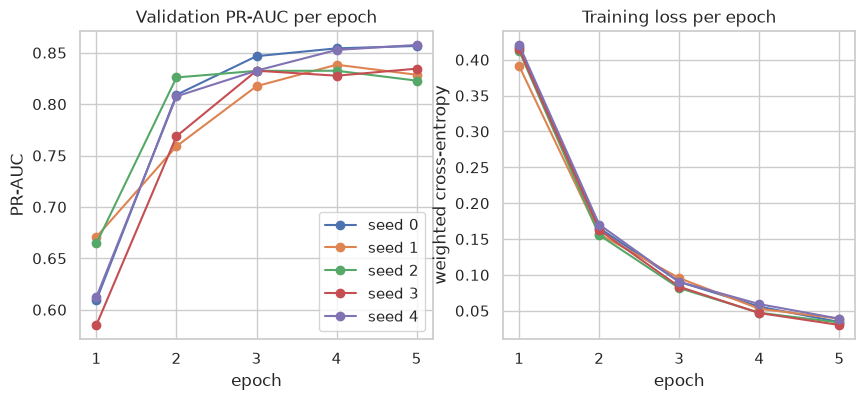

seconds per epoch: [75.0, 74.0, 74.0, 74.0, 75.0, 75.0, 74.0, 74.0, 74.0, 74.0, 74.0, 74.0, 74.0, 74.0, 74.0, 70.0, 72.0, 74.0, 74.0, 74.0, 70.0, 74.0, 75.0, 75.0, 74.0]


In [16]:
import glob, json

# One row per (seed, epoch) from the history stored in each saved fine-tuning run.
rows = []
for path in sorted(glob.glob(os.path.join(OUT_DEEP, "bert_*_seed*.json"))):
    with open(path, encoding="utf-8") as f:
        rec = json.load(f)
    for h in rec.get("history", []):
        rows.append({"seed": rec["seed"], **h})
hist = pd.DataFrame(rows)

if hist.empty:
    print("no fine-tuning history found yet")
else:
    # Left: validation PR-AUC per epoch. Right: training loss per epoch. One line per seed.
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for seed, g in hist.groupby("seed"):
        axes[0].plot(g["epoch"], g["val_pr_auc"], marker="o", label=f"seed {seed}")
        axes[1].plot(g["epoch"], g["train_loss"], marker="o", label=f"seed {seed}")
    axes[0].set_title("Validation PR-AUC per epoch"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("PR-AUC")
    axes[1].set_title("Training loss per epoch"); axes[1].set_xlabel("epoch"); axes[1].set_ylabel("weighted cross-entropy")
    axes[0].legend()
    plt.show()

    # Time per epoch decides whether to run all five seeds.
    print("seconds per epoch:", hist["seconds"].round(0).tolist())

## Findings (classical models)

Numbers are the means over the 5 split seeds in the first table, test split.

- Every text-based model beats the dummy floor by a wide margin (test PR-AUC 0.82 to
  0.85 against 0.049).
- Logistic regression with TF-IDF, with BM25, and the MLP are within seed noise of each
  other: the spread across seeds (about 0.07) is larger than the gaps between them.
- A single decision tree on sparse TF-IDF is far weaker (test PR-AUC about 0.40).
- Every model fits the training rows almost perfectly, so there is a large
  generalisation gap (train minus test PR-AUC about 0.15 to 0.17 for the linear models
  and the MLP).
- Caveat: the dataset marks real ads from some countries (for example Greece) as 0%
  fraud, so part of the signal may come from how the data was collected.

## Findings (deep models)

Numbers are test PR-AUC, means over the 5 split seeds (DistilBERT: 5 epochs, batch 128, texts cut
at 256 tokens, best epoch on validation kept).

- Frozen MiniLM embeddings are clearly worse than TF-IDF: the MLP head reaches 0.63 and the
  logistic regression head 0.52, against 0.82 to 0.85 for the TF-IDF models. DistilBERT beats the
  MLP head on all 5 seeds, by 0.20 on average. A single 384-number sentence vector loses what the
  sparse word features keep (a guess, not tested).
- Fine-tuned DistilBERT reaches 0.831 (std 0.066), between logistic regression with TF-IDF (0.821)
  and the best classical models (BM25 logistic regression 0.847, MLP 0.846). It does not clearly
  beat the classical models: per seed it is ahead of BM25 logistic regression on 1 seed of 5 (mean
  difference -0.016, std 0.016) and of the TF-IDF MLP on 1 of 5 (-0.015, std 0.034), and ahead of plain
  TF-IDF logistic regression on 2 of 5 (+0.010, std 0.037). With 5 seeds these gaps are too small
  to rank the models.
- All the TF-IDF models and DistilBERT move together across seeds (seed 2 is hard for every
  model, seeds 3 and 4 are easy), so much of the spread likely comes from which ads land in the test
  split rather than from the model (not tested separately).
- Cost per seed (mean seconds in the fit-time table): DistilBERT about 7 minutes on one GPU; the
  tuned TF-IDF logistic regressions 1 to 1.5 minutes; the tuned TF-IDF MLP about 7 minutes. The
  logistic regressions match DistilBERT's PR-AUC at a fraction of the time.
- The best epoch on validation varied: epoch 5 for seeds 0, 3 and 4, epoch 4 for seed 1, epoch 3
  for seed 2. Validation PR-AUC flattens after epoch 3 to 4, so more epochs would add little.
- The validation-chosen threshold of DistilBERT is unstable (0.26 to 0.95 across seeds), which
  affects its F1 (0.77 on average) but not PR-AUC.
- Not measured: how many ads exceed 256 tokens, so the truncation cost is unknown.